# 08.7 · Images as numbers; convolution by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/07-images-and-convolution/lesson.ipynb)

Read the [README](README.md) first and do the 5×5 convolution on paper. This notebook repeats it in NumPy and in Keras (the numbers match), then shows what real filters see in a ShopWave product photo.

Everything here runs on a laptop CPU in seconds.

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow's C++ start-up messages
warnings.filterwarnings("ignore")                # hide library deprecation notices
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
keras.utils.set_random_seed(42)                  # same start every run (results still vary slightly by machine)
print("Keras", keras.__version__, "· backend", keras.backend.backend())

Keras 3.15.1 · backend tensorflow


## 1. A photo is a grid of numbers

Fashion-MNIST is 70,000 small greyscale product photos (clothes, shoes, bags), 28×28 pixels each. We use it all through 08.7 and 08.8.

In [2]:
(x_train, y_train), _ = keras.datasets.fashion_mnist.load_data()
img = x_train[0]
print("shape:", img.shape, " dtype:", img.dtype, " min:", img.min(), " max:", img.max())
print("all training pixels: mean", round(x_train.mean(), 1), " share that are exactly 0:",
      round((x_train == 0).mean(), 3))

shape: (28, 28)  dtype: uint8  min: 0  max: 255
all training pixels: mean 72.9  share that are exactly 0: 0.502


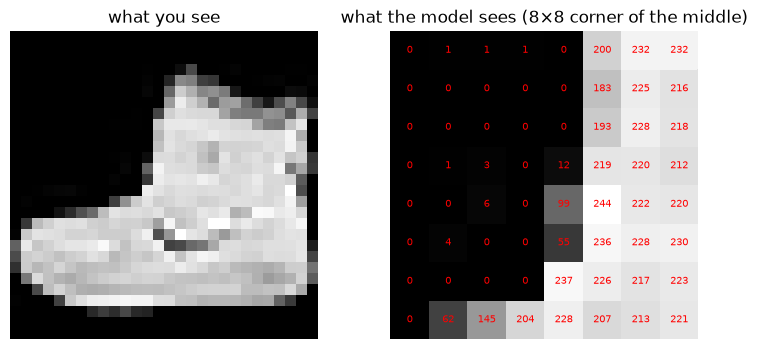

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("what you see")
axes[1].imshow(img[8:16, 8:16], cmap="gray")
for (r, c), v in np.ndenumerate(img[8:16, 8:16]):
    axes[1].text(c, r, v, ha="center", va="center", fontsize=7, color="red")
axes[1].set_title("what the model sees (8×8 corner of the middle)")
for a in axes: a.axis("off")
plt.show()

**Scaling.** Networks learn best when inputs are small numbers around 0–1, so we divide by 255. Nothing about the picture changes; only the units do.

In [4]:
img_scaled = img / 255.0
print("before:", img[14, 10:16])
print("after: ", img_scaled[14, 10:16].round(3))

before: [  0   0 237 226 217 223]
after:  [0.    0.    0.929 0.886 0.851 0.875]


**Colour** adds a third axis: height × width × channels, with one channel each for red, green and blue. Here is a tiny 2×3 colour image built by hand.

shape (H, W, C): (2, 3, 3) → 18 numbers


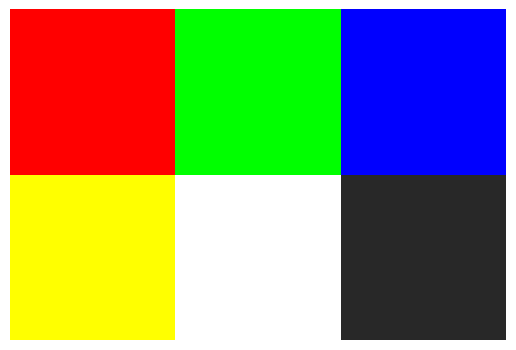

In [5]:
tiny = np.zeros((2, 3, 3), dtype="uint8")       # 2 rows, 3 columns, 3 channels
tiny[0, 0] = [255, 0, 0]       # red
tiny[0, 1] = [0, 255, 0]       # green
tiny[0, 2] = [0, 0, 255]       # blue
tiny[1, 0] = [255, 255, 0]     # red + green = yellow
tiny[1, 1] = [255, 255, 255]   # all three = white
tiny[1, 2] = [40, 40, 40]      # a little of each = dark grey
print("shape (H, W, C):", tiny.shape, "→", tiny.size, "numbers")
plt.imshow(tiny); plt.axis("off"); plt.show()

## 2. Convolution by hand, in NumPy

The same 5×5 image and vertical-edge filter as the README.

In [6]:
image = np.array([[0, 0, 0, 0, 0],
                  [0, 0, 9, 9, 9],
                  [0, 0, 9, 9, 9],
                  [0, 0, 9, 9, 9],
                  [0, 0, 0, 0, 0]], dtype=float)
vertical_edge = np.array([[-1, 0, 1],
                          [-1, 0, 1],
                          [-1, 0, 1]], dtype=float)

def conv2d(img, kernel, stride=1, pad=0):
    """Slide the kernel over the image; each output = sum of (patch × kernel)."""
    img = np.pad(img, pad)
    k = kernel.shape[0]
    n_out = (img.shape[0] - k) // stride + 1
    out = np.zeros((n_out, n_out))
    for i in range(n_out):
        for j in range(n_out):
            patch = img[i * stride:i * stride + k, j * stride:j * stride + k]
            out[i, j] = (patch * kernel).sum()
    return out

out = conv2d(image, vertical_edge)
print(out)

[[18. 18.  0.]
 [27. 27.  0.]
 [18. 18.  0.]]


Check one cell the long way, exactly as on paper: the top-left 3×3 patch times the filter.

In [7]:
patch = image[0:3, 0:3]
print("patch:\n", patch)
print("patch × filter:\n", patch * vertical_edge + 0.0)
print("sum =", (patch * vertical_edge + 0.0).sum())

patch:
 [[0. 0. 0.]
 [0. 0. 9.]
 [0. 0. 9.]]
patch × filter:
 [[0. 0. 0.]
 [0. 0. 9.]
 [0. 0. 9.]]
sum = 18.0


Now Keras. A `Conv2D` layer holds exactly this kind of filter; normally it *learns* the numbers, but we can set them by hand and check that it computes the same thing.

Keras wants a batch of images with a channel axis: shape `(1, 5, 5, 1)`.

In [8]:
conv = layers.Conv2D(filters=1, kernel_size=3, use_bias=False)
conv.build((None, 5, 5, 1))
conv.set_weights([vertical_edge.reshape(3, 3, 1, 1)])
keras_out = conv(image.reshape(1, 5, 5, 1)).numpy()[0, :, :, 0]
print(keras_out)
print("same as NumPy:", np.allclose(keras_out, out))

[[18. 18.  0.]
 [27. 27.  0.]
 [18. 18.  0.]]
same as NumPy: True


## 3. Stride and padding

Output size: $\;n_{out} = \left\lfloor \dfrac{n + 2p - k}{s} \right\rfloor + 1$

The table computes it with the formula and then asks Keras for the real shape.

In [9]:
cases = [(5, 3, 0, 1), (5, 3, 1, 1), (5, 3, 0, 2), (28, 3, 0, 1), (28, 5, 0, 1), (28, 3, 1, 2)]
print(f"{'n':>3} {'k':>2} {'p':>2} {'s':>2} {'formula':>8} {'Keras':>6}")
for n, k, p, s in cases:
    formula = (n + 2 * p - k) // s + 1
    x = layers.ZeroPadding2D(p)(np.zeros((1, n, n, 1))) if p else np.zeros((1, n, n, 1))
    shape = layers.Conv2D(1, k, strides=s)(x).shape[1]
    print(f"{n:>3} {k:>2} {p:>2} {s:>2} {formula:>8} {shape:>6}")

  n  k  p  s  formula  Keras
  5  3  0  1        3      3
  5  3  1  1        5      5
  5  3  0  2        2      2
 28  3  0  1       26     26
 28  5  0  1       24     24
 28  3  1  2       14     14


`padding="same"` in Keras adds just enough zeros to keep the size when the stride is 1, so you rarely type the padding yourself. Padding the 5×5 image by one keeps a 5×5 output and lets the filter see the borders:

In [10]:
print(conv2d(image, vertical_edge, pad=1))

[[  0.   9.   9.   0.  -9.]
 [  0.  18.  18.   0. -18.]
 [  0.  27.  27.   0. -27.]
 [  0.  18.  18.   0. -18.]
 [  0.   9.   9.   0.  -9.]]


## 4. Max pooling by hand

Take each 2×2 block, keep its largest number. The image halves in each direction; the strongest responses survive.

In [11]:
grid = np.array([[1, 3, 2, 0],
                 [4, 6, 1, 1],
                 [0, 2, 5, 7],
                 [1, 1, 3, 8]], dtype=float)
by_hand = grid.reshape(2, 2, 2, 2).max(axis=(1, 3))     # 2×2 blocks, max of each
keras_pool = layers.MaxPooling2D(2)(grid.reshape(1, 4, 4, 1)).numpy()[0, :, :, 0]
print(by_hand)
print("same as Keras:", np.allclose(by_hand, keras_pool))

[[6. 2.]
 [2. 8.]]
same as Keras: True


## 5. What filters see in a real product photo

Four classic hand-made filters applied to one Fashion-MNIST image. In 08.8 the network learns its own filters; these show the kind of thing first-layer filters end up detecting.

In [12]:
filters = {
    "vertical edges":   vertical_edge,
    "horizontal edges": vertical_edge.T,
    "blur":             np.ones((3, 3)) / 9,
    "sharpen":          np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
}
photo = x_train[0] / 255.0
maps = {name: conv2d(photo, k) for name, k in filters.items()}
for name, m in maps.items():
    print(f"{name:<17} output {m.shape}, range {m.min():6.2f} to {m.max():5.2f}")

vertical edges    output (26, 26), range  -2.89 to  2.77
horizontal edges  output (26, 26), range  -2.87 to  2.63
blur              output (26, 26), range   0.00 to  0.91
sharpen           output (26, 26), range  -1.73 to  2.65


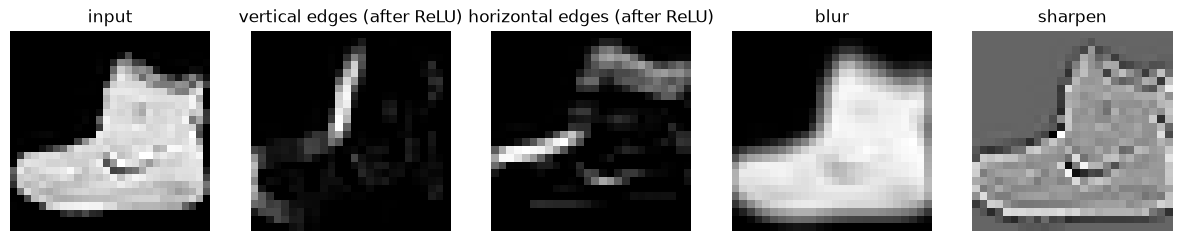

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
axes[0].imshow(photo, cmap="gray"); axes[0].set_title("input")
for ax, (name, m) in zip(axes[1:], maps.items()):
    ax.imshow(np.maximum(m, 0) if "edges" in name else m, cmap="gray")
    ax.set_title(name + (" (after ReLU)" if "edges" in name else ""))
for a in axes: a.axis("off")
plt.show()

The edge maps light up only where brightness changes: the outline of the boot and the stitching. Flat areas become 0. After ReLU (keep positives, zero the rest) each map keeps one direction of change, which is why networks learn pairs of opposite filters.

## 6. Shapes through a small CNN

No training yet: just watch the image shrink and the channels grow. You will train this exact network in 08.8.

In [14]:
cnn = keras.Sequential([
    keras.Input((28, 28, 1)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
])
x = np.zeros((1, 28, 28, 1))
for layer in cnn.layers:
    x = layer(x)
    print(f"{type(layer).__name__:<13} → {tuple(x.shape[1:])}")

Conv2D        → (26, 26, 16)
MaxPooling2D  → (13, 13, 16)
Conv2D        → (11, 11, 32)
MaxPooling2D  → (5, 5, 32)
Flatten       → (800,)


28 → 26 (3×3 filter, no padding) → 13 (pool) → 11 → 5 (pool rounds down) → 5 × 5 × 32 = 800 numbers for the classifier at the end.

## Quiz answers

1. Height × width × channels: `(160, 160, 3)`, 76,800 numbers.
2. So inputs are small numbers of similar size, which makes gradient descent stable; the picture itself does not change.
3. $\lfloor (32 + 0 - 5)/1 \rfloor + 1 = 28$.
4. 2×2 max pooling with stride 2 halves height and width and keeps the strongest response in each block; there are no weights to learn.
5. A 3×3 filter has 9 weights (plus a bias) whatever the image size, and the same weights are reused at every position. A dense layer needs one weight per pixel per neuron.

**Next:** [08.8 CNNs on Fashion-MNIST](../08-cnns-fashion-mnist/)